# GRANAP, 3: combine parameters

**What you will learn:** generate sections on a grid of values of two parameters, gather the results in one table,
and read how the two parameters act together.

**You need:** tutorial 2. **Run time:** about 20 seconds.

## 1. A grid of two parameters

The cortex's thickness depends on its number of layers and on the size of its cells. Each combination of three values
of each is generated: 9 sections, all with the same seed, so that only the parameters differ.

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.granap.simulation import simulate

layer_values = [3, 5, 7]                       # cortex layers (the default is 5)
diameter_values = [0.03, 0.04, 0.05]           # cortex cell diameter, mm (the default is 0.04)

rows = []
for n_layers, diameter in itertools.product(layer_values, diameter_values):
    totals = simulate({"cortex": {"n_layers": n_layers, "cell_diameter": diameter, "cell_width": diameter}}).totals
    rows.append({"n_layers": n_layers, "cell_diameter": diameter, **totals})
grid = pd.DataFrame(rows)
grid

,n_layers,cell_diameter,radius,area,cells,vessels,mean_vessel_diameter,air_share
0,3,0.03,0.300285,0.283281,868.0,15.0,27.469850,0.022597
1,3,0.04,0.330299,0.342741,862.0,15.0,27.469648,0.026716
2,3,0.05,0.360282,0.407789,865.0,15.0,27.469317,0.030126
3,5,0.03,0.360282,0.407789,1024.0,15.0,27.469571,0.029423
4,5,0.04,0.410287,0.528841,1013.0,15.0,27.492075,0.033770
5,5,0.05,0.460288,0.665595,1019.0,15.0,27.492117,0.035631
6,7,0.03,0.420282,0.554920,1205.0,15.0,27.492354,0.033491
7,7,0.04,0.490292,0.755194,1190.0,15.0,27.492076,0.037341
8,7,0.05,0.560282,0.986197,1197.0,15.0,27.491668,0.039332


(The cells' width along the ring follows their diameter here, so that they stay round.)

## 2. Read the table as a map

`pivot` arranges one output as a table, the layers in rows and the cell diameter in columns:

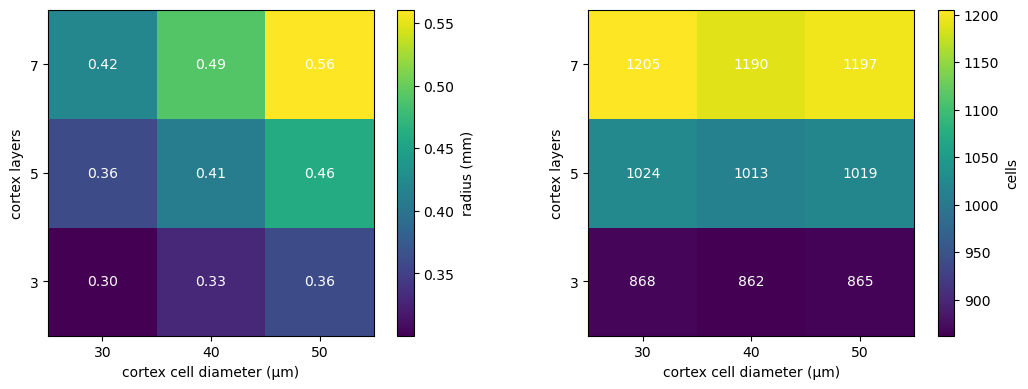

In [2]:
radius = grid.pivot(index="n_layers", columns="cell_diameter", values="radius")
cells = grid.pivot(index="n_layers", columns="cell_diameter", values="cells")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, table, label, digits in ((axes[0], radius, "radius (mm)", 2), (axes[1], cells, "cells", 0)):
    image = ax.imshow(table.values, origin="lower", cmap="viridis")
    ax.set_xticks(range(len(diameter_values)), [f"{v * 1000:.0f}" for v in diameter_values])
    ax.set_yticks(range(len(layer_values)), layer_values)
    ax.set_xlabel("cortex cell diameter (µm)"); ax.set_ylabel("cortex layers")
    for (i, j), value in np.ndenumerate(table.values):
        ax.text(j, i, f"{value:.{digits}f}", ha="center", va="center", color="w")
    fig.colorbar(image, ax=ax, label=label)
plt.tight_layout()

**Reading the maps.**

- **Radius.** The cortex adds its number of layers times its cells' diameter. The two parameters **interact**: going
  from 30 to 50 µm cells adds 60 µm to the radius with 3 layers, but 140 µm with 7 layers.
- **Cells.** More layers mean more cells: 150 to 180 more for two more layers. The cells' size has almost no effect: larger
  cells mean fewer cells in each ring, but a wider section with longer rings, and the two compensate.

This kind of interaction cannot be seen by changing one parameter at a time.

## 3. The same with lines

The radius against the number of layers, one line per cell diameter: the slopes differ, the signature of the
interaction.

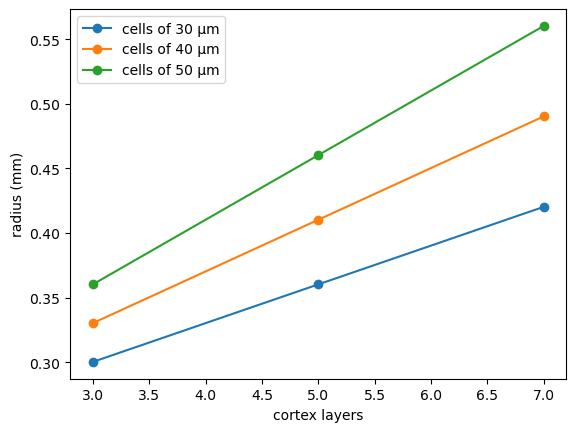

In [3]:
for diameter, rows_of_diameter in grid.groupby("cell_diameter"):
    plt.plot(rows_of_diameter["n_layers"], rows_of_diameter["radius"], marker="o",
             label=f"cells of {diameter * 1000:.0f} µm")
plt.xlabel("cortex layers"); plt.ylabel("radius (mm)"); plt.legend();

## Try it yourself

1. Replace the cell diameter by the stele's diameter (`{"stele": {"thickness": ...}}`: try 0.2, 0.27, 0.35). Does it
   interact with the cortex layers on the radius?
2. Map the air share instead of the radius for the aerenchyma proportion (0.1, 0.2, 0.3) and the cortex layers.
3. A grid of 5 × 5 values costs 25 sections: how long would it take here? This is why the next tutorial uses cleverer
   designs.

**Next:** `04_sensitivity_analysis.ipynb`.